SPDX-FileCopyrightText: 2026-present Marta Szulca (tusiya) <szulcam2410@gmail.com>, Hubert Stankiewicz (limebel) <stankiewicz.huberto@gmail.com>

SPDX-License-Identifier: MIT

In [3]:
import pandas as pd
import csv

from model_elements import (
    load_standard_quality_model,
    load_procedure_inputs_from_csv,
    load_weights_from_csv,
    CompositeElement,
    ProcedureElement,
    WeightedAverageStrategy,
    EvaluationScenario,
)

import visualizations as viz

In [11]:
import importlib
importlib.reload(vi)

<module 'variants.intuition' from '/home/marta/thesis/code/cloudquality/src/cloudquality/variants/intuition.py'>

In [12]:
import variants.intuition as vi
base_data, options = vi.prepare_intuition()



DOSTĘPNE KATEGORIE UŻYTKOWNIKÓW:

Wiek
──────────────────────────────────────────────────
  1 │ 18 - 24
  2 │ 45 - 54
  3 │ 25 - 34
  4 │ 35 - 44

Grupa
──────────────────────────────────────────────────
  5 │ W ramach spotkań z klientami, pracy zdalnej, itp.
  6 │ Jako student

Częstotliwość użytkowania
──────────────────────────────────────────────────
  7 │ Codziennie lub prawie codziennie

Kompetencje cyfrowe
──────────────────────────────────────────────────
  8 │ Bardzo wysoki - często pomagam innym w obsłudze programów oraz sprawnie uczę się nowych
  9 │ Wysoki - swobodnie korzystam z większości programów i zazwyczaj samodzielnie radzę sobie z nowymi lub nietypowymi zadaniami
 10 │ Średni - radzę sobie z podstawową obsługą programów, ale w przypadku trudniejszych zadań często potrzebuję pomocy


In [5]:
filtered_survey = vi.intuition(base_data, options, [2])
# filtered_survey = vi.intuition(base_data, options)


Respondents included: 10
Exported 33 hierarchy relationships.


In [42]:
import importlib
importlib.reload(viz)

<module 'visualizations' from '/home/marta/thesis/code/cloudquality/src/cloudquality/visualizations.py'>


Generating respondent demographics...
Selected respondents: 10

Wiek
Wiek
45 - 54    10
Name: count, dtype: int64

Grupa
Grupa
W ramach spotkań z klientami, pracy zdalnej, itp.    7
Jako wykładowca / nauczyciel                         3
Name: count, dtype: int64

Częstotliwość użytkowania
Częstotliwość użytkowania
Codziennie lub prawie codziennie     7
Kilka (2-5) razy w miesiącu          2
Raz na trzy miesiące lub rzadziej    1
Name: count, dtype: int64

Kompetencje cyfrowe
Kompetencje cyfrowe
Średni - radzę sobie z podstawową obsługą programów, ale w przypadku trudniejszych zadań często potrzebuję pomocy              4
Wysoki - swobodnie korzystam z większości programów i zazwyczaj samodzielnie radzę sobie z nowymi lub nietypowymi zadaniami    4
Bardzo wysoki - często pomagam innym w obsłudze programów oraz sprawnie uczę się nowych                                        2
Name: count, dtype: int64


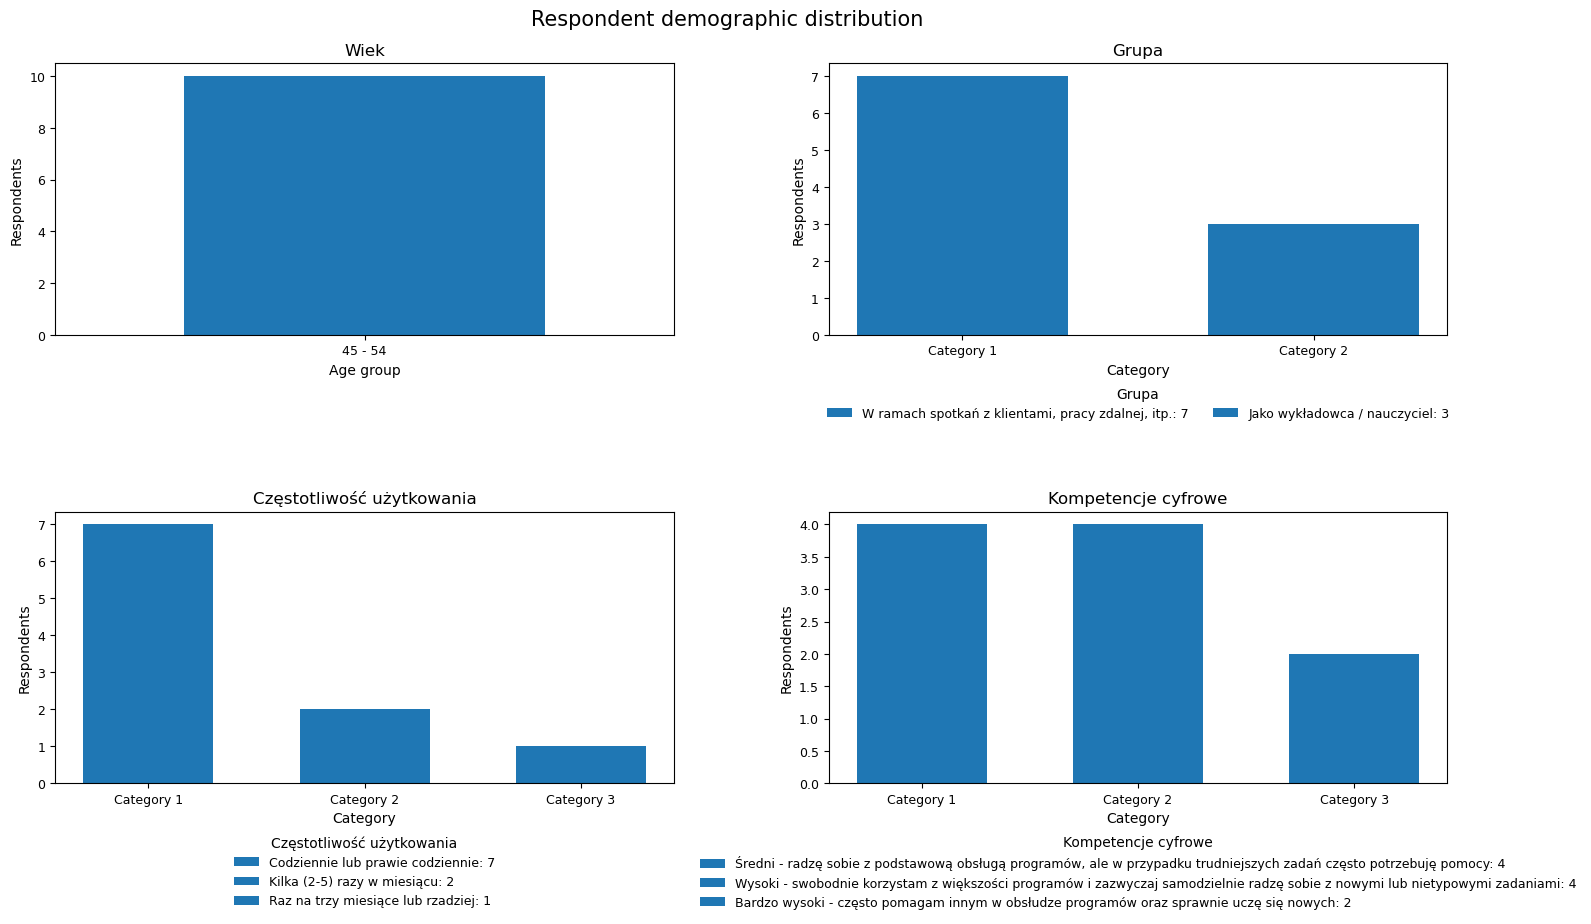

In [43]:
viz.generate_demographic_visualizations(filtered_survey)

files

In [44]:
SYSTEM_FILE = "../../system_metrics.csv"
SURVEY_FILE = "../../user_surveys.csv"
WEIGHTS_FILE = "../../weights.csv"

OUTPUT_FILE = "../../aggregation_comparison.csv"

data loading

In [45]:
model = load_standard_quality_model()

system_inputs = load_procedure_inputs_from_csv(SYSTEM_FILE)

survey_df = pd.read_csv(SURVEY_FILE, encoding="utf-8-sig")
survey_df = survey_df.apply(pd.to_numeric, errors="coerce")

# Mean score for each procedure across respondents
survey_scores = survey_df.mean().to_dict()

ahp_weights = load_weights_from_csv(WEIGHTS_FILE)

In [46]:
def complete_weights(element, supplied_weights):
    result = {}

    if not isinstance(element, CompositeElement):
        return result

    provided = supplied_weights.get(element.name, {})

    result[element.name] = {
        child.name: float(provided.get(child.name, 1.0))
        for child in element.subelements
    }

    for child in element.subelements:
        result.update(complete_weights(child, supplied_weights))

    return result

In [47]:
complete_ahp_weights = complete_weights(model, ahp_weights)

In [48]:
weighted_average = WeightedAverageStrategy()

def calculate(element, scores, weights):
    """Recursively aggregate procedure scores."""

    if isinstance(element, ProcedureElement):
        if element.name not in scores:
            raise KeyError(f"Missing score for: {element.name}")
        return float(scores[element.name])

    child_scores = [
        calculate(child, scores, weights)
        for child in element.subelements
    ]

    child_weights = [
        weights[element.name][child.name]
        for child in element.subelements
    ]

    return weighted_average.aggregate(child_scores, child_weights)

scores

In [49]:
def transform_system_metrics(element):
    """Calculate transformed scores for all procedure nodes."""
    scores = {}

    def visit(node):
        if isinstance(node, ProcedureElement):
            if node.name not in system_inputs:
                raise KeyError(f"Missing system metric: {node.name}")

            scores[node.name] = node.default_strategy.evaluate(
                system_inputs[node.name]
            )
        else:
            for child in node.subelements:
                visit(child)

    visit(element)
    return scores

In [50]:
system_scores = transform_system_metrics(model)

Analytical model

In [51]:
equal_weights = complete_weights(model, {})

scenario_1 = calculate(
    model,
    system_scores,
    equal_weights
)

Intuitive model

In [52]:
scenario_2 = calculate(
    model,
    survey_scores,
    complete_ahp_weights
)

hybrid model

In [53]:
scenario_3 = calculate(
    model,
    system_scores,
    complete_ahp_weights
)

results

In [54]:
results = {
    "System metrics + equal weights": {},
    "User surveys + AHP weights": {},
    "System metrics + AHP weights": {}
}

scenarios = [
    ("System metrics + equal weights", system_scores, equal_weights),
    ("User surveys + AHP weights", survey_scores, complete_ahp_weights),
    ("System metrics + AHP weights", system_scores, complete_ahp_weights),
]

for label, scores, weights in scenarios:
    results[label]["Model jakości"] = calculate(model, scores, weights)

    for child in model.subelements:
        results[label][child.name] = calculate(child, scores, weights)

display

In [55]:
comparison = pd.DataFrame(results)
comparison.index.name = "Criterion"

print("\n========== AGGREGATION COMPARISON ==========\n")
print(comparison.round(3).to_string())

comparison.round(4).to_csv(
    OUTPUT_FILE,
    encoding="utf-8-sig"
)

print(f"\nResults saved to: {OUTPUT_FILE}")


========== AGGREGATION COMPARISON ==========

                System metrics + equal weights  User surveys + AHP weights  System metrics + AHP weights
Criterion                                                                                               
Model jakości                            4.268                       3.890                         3.807
Funkcjonalność                           4.820                       4.008                         4.791
Wydajność                                4.450                       3.984                         4.462
Satysfakcja                              3.211                       3.775                         3.210
Wiarygodność                             4.000                       4.200                         4.000
Elastyczność                             4.126                       3.972                         4.154
Ochrona                                  5.000                       4.000                         5.000

Results

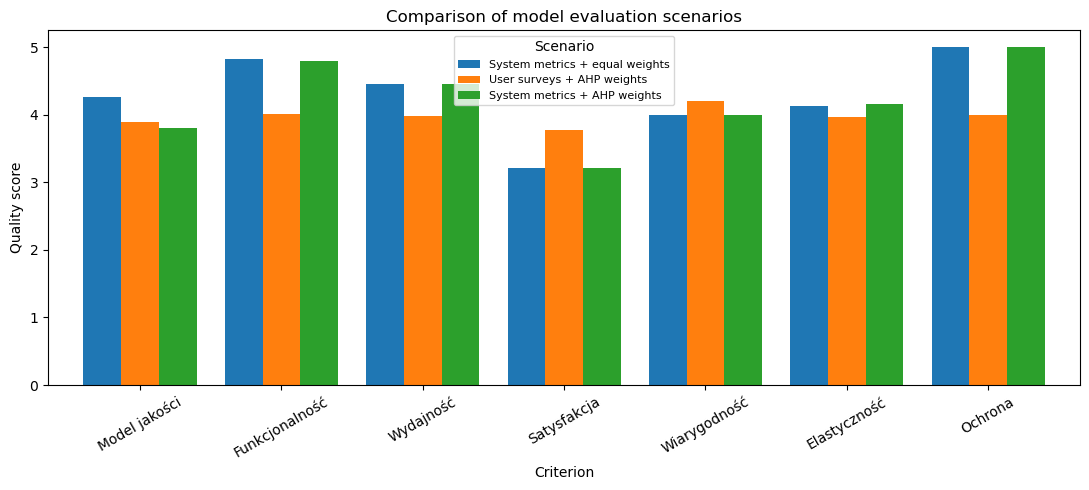

In [56]:
viz.generate_model_comparison_visualizations(comparison)